# 04.7 · Cross-validation: a fairer score

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/04-trustworthy-models/07-cross-validation/lesson.ipynb)

Read the [README](README.md) first and do the five folds on paper. This notebook checks your folds, then uses cross-validation on the real churn table to (1) measure how much a single split wobbles, (2) choose KNN's *k* honestly and (3) re-judge the feature-engineering gain from 04.6.

## 1. The ten customers

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

ten = pd.DataFrame({
    "row": range(1, 11),
    "days_since_last": [5, 80, 12, 60, 28, 95, 42, 18, 72, 52],
    "churned":         [0,  1,  0,  1,  0,  1,  1,  0,  0,  1],
})
X10, y10 = ten[["days_since_last"]], ten["churned"]
ten

,row,days_since_last,churned
0,1,5,0
1,2,80,1
2,3,12,0
3,4,60,1
4,5,28,0
5,6,95,1
6,7,42,1
7,8,18,0
8,9,72,0
9,10,52,1


## 2. Which rows land in which fold?

`KFold(n_splits=5)` without shuffling cuts the rows into five consecutive blocks of two. Compare with your paper.

In [2]:
from sklearn.model_selection import KFold
kf = KFold(n_splits=5)
for fold, (train_idx, test_idx) in enumerate(kf.split(X10), start=1):
    print(f"fold {fold}: test rows {list(ten['row'].iloc[test_idx])}   train rows {list(ten['row'].iloc[train_idx])}")

fold 1: test rows [1, 2]   train rows [3, 4, 5, 6, 7, 8, 9, 10]
fold 2: test rows [3, 4]   train rows [1, 2, 5, 6, 7, 8, 9, 10]
fold 3: test rows [5, 6]   train rows [1, 2, 3, 4, 7, 8, 9, 10]
fold 4: test rows [7, 8]   train rows [1, 2, 3, 4, 5, 6, 9, 10]
fold 5: test rows [9, 10]   train rows [1, 2, 3, 4, 5, 6, 7, 8]


## 3. Train and score five times

The model is 1-nearest-neighbour on `days_since_last`: a test customer gets the label of the closest training customer. Each fold trains on 8 rows and is scored on the other 2.

In [3]:
from sklearn.neighbors import KNeighborsClassifier
scores = []
for fold, (tr, te) in enumerate(kf.split(X10), start=1):
    model = KNeighborsClassifier(n_neighbors=1).fit(X10.iloc[tr], y10.iloc[tr])
    pred = model.predict(X10.iloc[te])
    acc = (pred == y10.iloc[te].to_numpy()).mean()
    scores.append(acc)
    print(f"fold {fold}: test days {X10.iloc[te, 0].tolist()}  predicted {pred.tolist()}  true {y10.iloc[te].tolist()}  acc {acc:.1f}")
scores = np.array(scores)
print(f"\nmean {scores.mean():.2f}   std {scores.std():.3f}")

fold 1: test days [5, 80]  predicted [0, 0]  true [0, 1]  acc 0.5
fold 2: test days [12, 60]  predicted [0, 1]  true [0, 1]  acc 1.0
fold 3: test days [28, 95]  predicted [0, 1]  true [0, 1]  acc 1.0
fold 4: test days [42, 18]  predicted [1, 0]  true [1, 0]  acc 1.0
fold 5: test days [72, 52]  predicted [1, 1]  true [0, 1]  acc 0.5

mean 0.80   std 0.245


Folds 1 and 5 say 50%; folds 2, 3 and 4 say 100%. If you had made one train/test split you would have reported one of those, and either would be misleading. Cross-validation reports **0.80 ± 0.24**: the average, and how much it wobbles.

## 4. The one-liner

`cross_val_score` does the loop above for you.

In [4]:
from sklearn.model_selection import cross_val_score
s = cross_val_score(KNeighborsClassifier(n_neighbors=1), X10, y10, cv=KFold(5))
print(s, "→ mean", s.mean(), " std", round(s.std(), 3))

[0.5 1.  1.  1.  0.5] → mean 0.8  std 0.245


## 5. Real data: how much does one split wobble?

Back to the 3,317 ShopWave customers. We keep the same 25% test set as Module 03 locked away, and only ever cross-validate on the 2,487 training customers.

In [5]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")                       # ~1 s after the first run
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])
features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}")

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%
train 2,487 / test 830


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
single = []
for seed in range(20):                       # 20 different single splits of the training set
    a, b, ya, yb = train_test_split(X_train, y_train, test_size=0.25, random_state=seed, stratify=y_train)
    single.append(logreg.fit(a, ya).score(b, yb))
print(f"20 single splits: accuracy from {min(single):.3f} to {max(single):.3f}")

20 single splits: accuracy from 0.619 to 0.711


Same model, same data, only the luck of the split changes, and the "accuracy" ranges over about nine points. Any number from a single split carries that much noise.

In [7]:
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
s = cross_val_score(logreg, X_train, y_train, cv=skf)
print("fold accuracies:", s.round(3))
print(f"cross-validated accuracy: {s.mean():.3f} ± {s.std():.3f}")

fold accuracies: [0.651 0.701 0.662 0.692 0.72 ]
cross-validated accuracy: 0.685 ± 0.026


## 6. Stratified folds

`StratifiedKFold` makes every fold have the same churn rate as the whole training set. With plain `KFold` on data sorted in some way, one fold can end up mostly churners. Compare:

In [8]:
sorted_y = y_train.sort_values().reset_index(drop=True)      # all 0s first, then all 1s
dummy_X = np.zeros((len(sorted_y), 1))
for name, cv in [("KFold", KFold(5)), ("StratifiedKFold", StratifiedKFold(5))]:
    rates = [sorted_y.iloc[te].mean() for _, te in cv.split(dummy_X, sorted_y)]
    print(f"{name:<16} churn rate per test fold: {np.round(rates, 2)}")

KFold            churn rate per test fold: [0.   0.   0.18 1.   1.  ]
StratifiedKFold  churn rate per test fold: [0.44 0.44 0.43 0.44 0.44]


Plain `KFold` on sorted data gives folds that are all stayers or all churners: useless. Stratified folds all sit at 44%. For classification, use `StratifiedKFold` (scikit-learn does so automatically when you pass `cv=5` to a classifier).

## 7. Choosing KNN's *k* with cross-validation

In Module 03 we tried several *k* on the test set. That quietly turns the test set into a training tool. The honest way: choose *k* by CV on the training set, then touch the test set **once**.

In [9]:
results = []
for k in [1, 5, 15, 31, 51, 101, 201]:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    s = cross_val_score(knn, X_train, y_train, cv=skf)
    results.append((k, s.mean(), s.std()))
    print(f"k={k:>3}: {s.mean():.3f} ± {s.std():.3f}")

k=  1: 0.597 ± 0.019
k=  5: 0.643 ± 0.021
k= 15: 0.647 ± 0.022


k= 31: 0.667 ± 0.025
k= 51: 0.672 ± 0.020


k=101: 0.682 ± 0.022


k=201: 0.680 ± 0.024


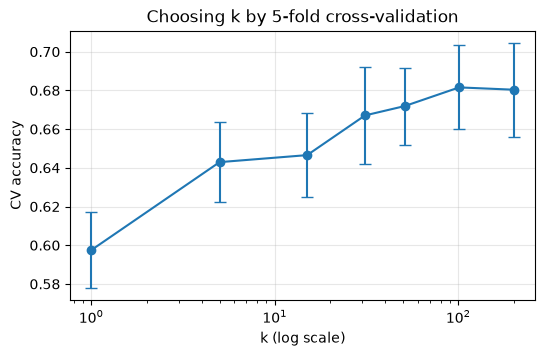

best k = 101;  one final look at the test set: 0.669


In [10]:
ks, means, stds = zip(*results)
plt.figure(figsize=(6, 3.5))
plt.errorbar(ks, means, yerr=stds, marker="o", capsize=4)
plt.xscale("log"); plt.xlabel("k (log scale)"); plt.ylabel("CV accuracy")
plt.title("Choosing k by 5-fold cross-validation"); plt.grid(alpha=.3); plt.show()

best_k = ks[int(np.argmax(means))]
final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)).fit(X_train, y_train)
print(f"best k = {best_k};  one final look at the test set: {final.score(X_test, y_test):.3f}")

CV picks *k* = 101 (0.682). The error bars overlap heavily from *k* = 31 upwards, though: those choices are statistically indistinguishable. Cross-validation tells you that too, which a single number never does.

The one look at the test set gives 0.669, slightly below the CV estimate and well inside its ± 0.022. That is what an honest final score looks like.

## 8. Was 04.6's feature-engineering gain real?

In 04.6, logging the skewed columns raised test AUC from 0.741 to 0.747. Check it with 5-fold CV on the training set:

In [11]:
for col in ["orders", "spend", "products", "days_since_last"]:
    X_train["log_" + col] = np.log1p(X_train[col])
raw_cols = ["orders", "spend", "products", "tenure_days", "days_since_last"]
log_cols = ["log_orders", "log_spend", "log_products", "tenure_days", "log_days_since_last"]
for name, cols in [("raw", raw_cols), ("logged", log_cols)]:
    s = cross_val_score(logreg, X_train[cols], y_train, cv=skf, scoring="roc_auc")
    print(f"{name:<7} AUC per fold {s.round(3)}  mean {s.mean():.3f} ± {s.std():.3f}")

raw     AUC per fold [0.705 0.759 0.707 0.754 0.776]  mean 0.740 ± 0.029
logged  AUC per fold [0.71  0.765 0.705 0.752 0.768]  mean 0.740 ± 0.027


Both average **0.740**. The logged version wins in two folds and loses in three. The +0.006 we saw in 04.6 was the luck of that particular test split, not a real improvement.

This is the most useful habit in the whole module: **before you believe a small improvement, cross-validate it and compare fold by fold.** Most "improvements" on a single split are noise.

## 9. Time series: never train on the future

For data ordered in time (monthly sales, Module 07), shuffled folds would let the model learn from next year to predict last year. `TimeSeriesSplit` always trains on the past and tests on what comes next:

In [12]:
from sklearn.model_selection import TimeSeriesSplit
months = np.arange(1, 13)
for fold, (tr, te) in enumerate(TimeSeriesSplit(n_splits=4, test_size=2).split(months), start=1):
    print(f"fold {fold}: train months {months[tr].tolist()}  →  test months {months[te].tolist()}")

fold 1: train months [1, 2, 3, 4]  →  test months [5, 6]
fold 2: train months [1, 2, 3, 4, 5, 6]  →  test months [7, 8]
fold 3: train months [1, 2, 3, 4, 5, 6, 7, 8]  →  test months [9, 10]
fold 4: train months [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]  →  test months [11, 12]


## Quiz answers

1. Every row is used for testing exactly once and for training *k* − 1 times.
2. 5 models are trained; each sees 80% of the rows.
3. The mean is the estimate of performance; the standard deviation shows how much it depends on which rows were tested. Report both.
4. Choosing *k* (or anything) by looking at test-set scores makes the test set part of training; its score is then optimistic. Use CV on the training set to choose, and the test set once at the end.
5. Use `StratifiedKFold` for classification (keeps the class balance in every fold) and `TimeSeriesSplit` for data ordered in time (never trains on the future).

**Next:** [04.8 Pipelines](../08-pipelines/)